In [14]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shristisaha903/dataset6/advanced_features_full_v2.csv
/kaggle/input/datasets/shristisaha903/dataset3/advanced_features_test.csv
/kaggle/input/datasets/shristisaha903/dataset5/advanced_features_full.csv


In [15]:
# ==========================================
# PATH SNAP: LIGHTGBM (Dataset 6)
# ==========================================
import pandas as pd
import numpy as np
import time
import joblib
import os
from sklearn.model_selection import GroupShuffleSplit
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

# 1. LOAD DATA
DATA_PATH = "/kaggle/input/datasets/shristisaha903/dataset6/advanced_features_full_v2.csv" 
print("Loading dataset...")
df = pd.read_csv(DATA_PATH)

exclude_cols = ['target', 'point_idx', 'trip_id', 'arc_id']
features = [c for c in df.columns if c not in exclude_cols]
X = df[features]
y = df["target"]

print(f"Using {len(features)} features.")

# 2. GROUP-AWARE SPLIT
print("Performing Group-Aware Split...")
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, val_idx = next(gss.split(X, y, groups=df['trip_id']))

X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

print(f"Training rows: {len(X_train)} | Validation rows: {len(X_val)}")
print(f"Training on {df.iloc[train_idx]['trip_id'].nunique()} trips, validating on {df.iloc[val_idx]['trip_id'].nunique()} trips.")

# 3. MODEL TRAINING
print("Training LightGBM...")
model = LGBMClassifier(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1 
)

start_train = time.time()
model.fit(X_train, y_train)
train_time = time.time() - start_train

# 4. EVALUATION
print("Evaluating...")
start_infer = time.time()
y_pred = model.predict(X_val)
y_prob = model.predict_proba(X_val)[:, 1]
infer_time = time.time() - start_infer

acc = accuracy_score(y_val, y_pred)
prec = precision_score(y_val, y_pred)
rec = recall_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
ll = log_loss(y_val, y_prob)

# Top-1 Accuracy
val_df = X_val.copy()
val_df["point_idx"] = df.loc[val_idx, "point_idx"]
val_df["target"] = y_val.values
val_df["prob"] = y_prob
val_df["pred"] = y_pred
top1_preds = val_df.loc[val_df.groupby("point_idx")["prob"].idxmax()]
top1_acc = (top1_preds["pred"] == top1_preds["target"]).mean()

# 5. PRINT RESULTS
print("\n=== LIGHTGBM (V2 FEATURES) ===")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"Log Loss:  {ll:.4f}")
print(f"Top-1 Acc: {top1_acc:.4f}")
print(f"Train Time: {train_time:.2f} seconds")
print(f"Infer Time: {infer_time:.4f} seconds")

# 6. SAVE
os.makedirs("/kaggle/working/artifacts", exist_ok=True)
joblib.dump(model, "/kaggle/working/artifacts/lightgbm_v2.pkl")
print("\nSaved model to /kaggle/working/artifacts/lightgbm_v2.pkl")

Loading dataset...
Using 25 features.
Performing Group-Aware Split...
Training rows: 443904 | Validation rows: 181347
Training on 56 trips, validating on 24 trips.
Training LightGBM...
Evaluating...

=== LIGHTGBM (V2 FEATURES) ===
Accuracy:  0.7074
Precision: 0.7148
Recall:    0.7032
F1-Score:  0.7089
Log Loss:  0.8329
Top-1 Acc: 0.5085
Train Time: 6.13 seconds
Infer Time: 1.5287 seconds

Saved model to /kaggle/working/artifacts/lightgbm_v2.pkl


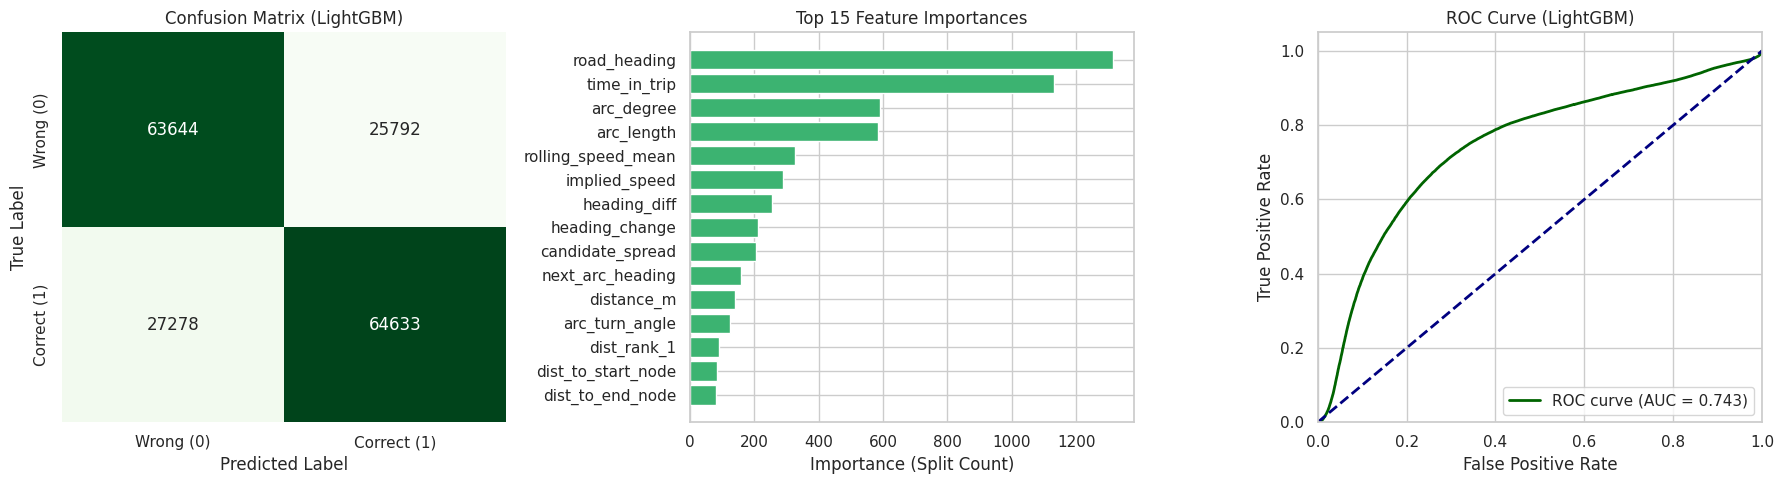

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

sns.set_theme(style="whitegrid")
plt.figure(figsize=(18, 5))

# 1. CONFUSION MATRIX
plt.subplot(1, 3, 1)
cm = confusion_matrix(y_val, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Wrong (0)', 'Correct (1)'],
            yticklabels=['Wrong (0)', 'Correct (1)'])
plt.title('Confusion Matrix (LightGBM)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# 2. FEATURE IMPORTANCE
plt.subplot(1, 3, 2)
importances = model.feature_importances_
indices = np.argsort(importances)

top_n = 15
plt.barh(range(top_n), importances[indices][-top_n:], color='mediumseagreen')
plt.yticks(range(top_n), [features[i] for i in indices][-top_n:])
plt.title('Top 15 Feature Importances')
plt.xlabel('Importance (Split Count)')

# 3. ROC CURVE
plt.subplot(1, 3, 3)
fpr, tpr, thresholds = roc_curve(y_val, y_prob)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, color='darkgreen', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (LightGBM)')
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [17]:
import joblib
import os

os.makedirs("/kaggle/working/artifacts", exist_ok=True)

model_path = "/kaggle/working/artifacts/lightgbm.pkl"
joblib.dump(model, model_path)

print(f"LightGBM model saved to: {model_path}")

LightGBM model saved to: /kaggle/working/artifacts/lightgbm.pkl


In [18]:
# ==========================================
# EXTRACT LIGHTGBM FEATURE IMPORTANCES
# ==========================================
import pandas as pd
import numpy as np

# Create a DataFrame of feature names and their LightGBM importances
lgb_importances_df = pd.DataFrame({
    'Feature': features,
    'Importance (Split Count)': model.feature_importances_
})

# Sort by importance (highest at the top)
lgb_importances_df = lgb_importances_df.sort_values(by='Importance (Split Count)', ascending=False).reset_index(drop=True)

print("=== LIGHTGBM FEATURE IMPORTANCES ===")
# Display all 24 features
print(lgb_importances_df.to_string(index=False))

=== LIGHTGBM FEATURE IMPORTANCES ===
           Feature  Importance (Split Count)
      road_heading                      1314
      time_in_trip                      1130
        arc_degree                       590
        arc_length                       584
rolling_speed_mean                       327
     implied_speed                       291
      heading_diff                       254
    heading_change                       213
  candidate_spread                       207
  next_arc_heading                       160
        distance_m                       141
    arc_turn_angle                       124
       dist_rank_1                        90
dist_to_start_node                        85
  dist_to_end_node                        82
           heading                        72
       dist_rank_0                        70
      acceleration                        54
         prev_dist                        53
             speed                        47
              rank

In [2]:
# ==========================================
# PATH SNAP: LOGISTIC REGRESSION (Dataset 6)
# ==========================================
import pandas as pd
import numpy as np
import time
import joblib
import os
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

# 1. LOAD DATA
DATA_PATH = "/kaggle/input/datasets/shristisaha903/dataset6/advanced_features_full_v2.csv" 
print("Loading dataset...")
df = pd.read_csv(DATA_PATH)

# Explicitly select the 12 features (including the 2 new ones)
# Note: If you use the dynamic method, ensure arc_id/point_idx/trip_id are excluded.
exclude_cols = ['target', 'point_idx', 'trip_id', 'arc_id']
features = [c for c in df.columns if c not in exclude_cols]

X = df[features]
y = df["target"]

print(f"Using {len(features)} features: {features}")

# 2. GROUP-AWARE SPLIT
print("Performing Group-Aware Split...")
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, val_idx = next(gss.split(X, y, groups=df['trip_id']))

X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

print(f"Training rows: {len(X_train)} | Validation rows: {len(X_val)}")
print(f"Training on {df.iloc[train_idx]['trip_id'].nunique()} trips, validating on {df.iloc[val_idx]['trip_id'].nunique()} trips.")

# 3. PREPROCESSING
print("Scaling features...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# 4. MODEL TRAINING
print("Training Logistic Regression...")
model = LogisticRegression(
    max_iter=1000, 
    random_state=42, 
    class_weight='balanced' 
)

start_train = time.time()
model.fit(X_train_scaled, y_train)
train_time = time.time() - start_train

# 5. EVALUATION
print("Evaluating...")
start_infer = time.time()
y_pred = model.predict(X_val_scaled)
y_prob = model.predict_proba(X_val_scaled)[:, 1]
infer_time = time.time() - start_infer

acc = accuracy_score(y_val, y_pred)
prec = precision_score(y_val, y_pred)
rec = recall_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
ll = log_loss(y_val, y_prob)

# Top-1 Accuracy
val_df = X_val.copy()
val_df["point_idx"] = df.loc[val_idx, "point_idx"]
val_df["target"] = y_val.values
val_df["prob"] = y_prob
val_df["pred"] = y_pred
top1_preds = val_df.loc[val_df.groupby("point_idx")["prob"].idxmax()]
top1_acc = (top1_preds["pred"] == top1_preds["target"]).mean()

# 6. PRINT RESULTS
print("\n=== LOGISTIC REGRESSION (V2 FEATURES) ===")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"Log Loss:  {ll:.4f}")
print(f"Top-1 Acc: {top1_acc:.4f}")
print(f"Train Time: {train_time:.2f} seconds")
print(f"Infer Time: {infer_time:.4f} seconds")

# 7. SAVE
os.makedirs("/kaggle/working/artifacts", exist_ok=True)
joblib.dump(model, "/kaggle/working/artifacts/logistic_regression_v2.pkl")
joblib.dump(scaler, "/kaggle/working/artifacts/scaler_v2.pkl")
print("\nSaved model and scaler to /kaggle/working/artifacts/")

Loading dataset...
Using 25 features: ['distance_m', 'rank', 'dist_to_start_node', 'dist_to_end_node', 'arc_length', 'road_heading', 'arc_degree', 'speed', 'acceleration', 'heading', 'heading_change', 'time_gap', 'rolling_speed_mean', 'rolling_speed_std', 'time_in_trip', 'heading_diff', 'dist_rank_0', 'dist_rank_1', 'candidate_spread', 'implied_speed', 'next_arc_heading', 'arc_turn_angle', 'prev_dist', 'prev_speed', 'time_since_prev']
Performing Group-Aware Split...
Training rows: 443904 | Validation rows: 181347
Training on 56 trips, validating on 24 trips.
Scaling features...
Training Logistic Regression...
Evaluating...

=== LOGISTIC REGRESSION (V2 FEATURES) ===
Accuracy:  0.7742
Precision: 0.7749
Recall:    0.7814
F1-Score:  0.7781
Log Loss:  0.5287
Top-1 Acc: 0.7567
Train Time: 6.96 seconds
Infer Time: 0.0332 seconds

Saved model and scaler to /kaggle/working/artifacts/


In [20]:
# Check if the correct road is even in the Top-3 candidates
# Group by point and see if the target 1 exists
true_arcs_in_candidates = val_df.groupby("point_idx")["target"].max()

miss_rate = 1 - true_arcs_in_candidates.mean()
print(f"\n=== CANDIDATE MISS RATE ===")
print(f"Percentage of GPS points where the correct road was NOT in the Top-3: {miss_rate:.2%}")
print(f"Percentage where it WAS in the Top-3: {true_arcs_in_candidates.mean():.2%}")


=== CANDIDATE MISS RATE ===
Percentage of GPS points where the correct road was NOT in the Top-3: 0.82%
Percentage where it WAS in the Top-3: 99.18%


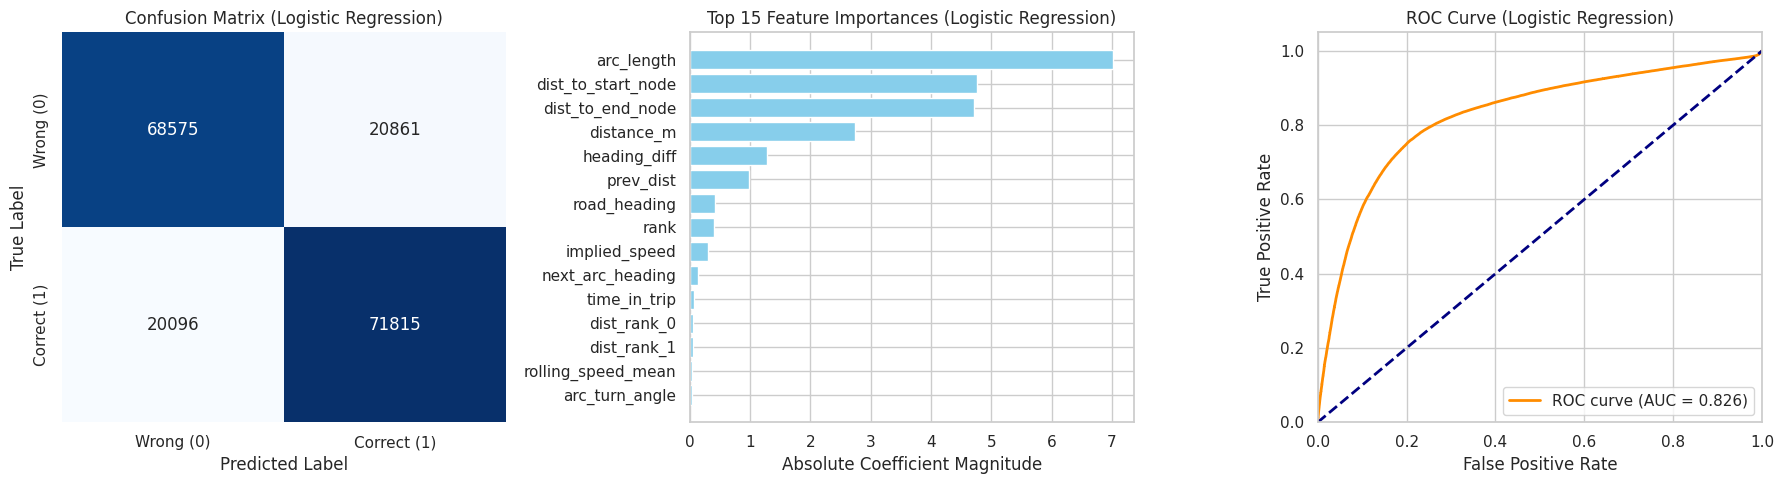

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

sns.set_theme(style="whitegrid")
plt.figure(figsize=(18, 5))

# 1. CONFUSION MATRIX
plt.subplot(1, 3, 1)
cm = confusion_matrix(y_val, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Wrong (0)', 'Correct (1)'],
            yticklabels=['Wrong (0)', 'Correct (1)'])
plt.title('Confusion Matrix (Logistic Regression)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# 2. FEATURE IMPORTANCE (The Fix)
plt.subplot(1, 3, 2)
# Use coef_ for Logistic Regression, NOT feature_importances_
importances = np.abs(model.coef_[0]) 
indices = np.argsort(importances)

top_n = 15
plt.barh(range(top_n), importances[indices][-top_n:], color='skyblue')
plt.yticks(range(top_n), [features[i] for i in indices][-top_n:])
plt.title('Top 15 Feature Importances (Logistic Regression)')
plt.xlabel('Absolute Coefficient Magnitude')

# 3. ROC CURVE
plt.subplot(1, 3, 3)
fpr, tpr, thresholds = roc_curve(y_val, y_prob)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Logistic Regression)')
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()